# NN_L6_w2v_pca

**Two-dimensional principal-component projection of 32 words in four groups (monetary policy, energy, banking, digital payments) in our word2vec space trained on ECB speeches.**

Neural Networks and Deep Learning (NN), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L6/NN_L6_w2v_pca/NN_L6_w2v_pca.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Word vectors of skip-gram with negative sampling ($d=100$), centred and projected on two principal components.

variance kept by 2 components (%) = 31.9   [pca.var2_pct]


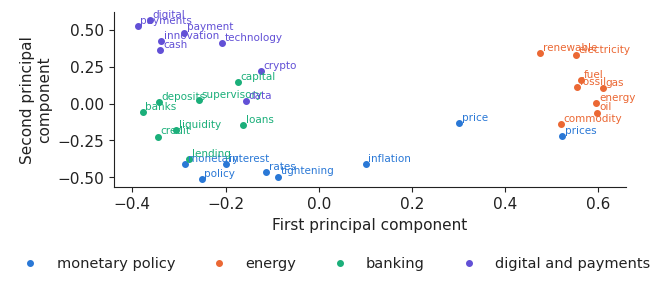

In [3]:
import json, urllib.request
_F = 'w2v_pca_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L6/NN_L6_w2v_pca/' + _F))
Z = np.array(R['vec']); g = R['group']; w = R['word']; Zc = Z - Z.mean(0); U, S, Vt = np.linalg.svd(Zc, full_matrices=False); P = Zc @ Vt[:2].T
show('pca.var2_pct', 'variance kept by 2 components (%)', round(100 * float((S[:2] ** 2).sum() / (S ** 2).sum()), 1))
col = {'monetary': PAL['data'], 'energy': PAL['model'], 'banking': PAL['benchmark'], 'digital': '#6250d6'}
name = {'monetary': 'monetary policy', 'energy': 'energy', 'banking': 'banking', 'digital': 'digital and payments'}
fig, ax = plt.subplots(figsize=(6.4, 2.9))
for k in col:
    ii = [i for i, x in enumerate(g) if x == k]; ax.scatter(P[ii, 0], P[ii, 1], color=col[k], s=16, label=name[k])
    for i in ii: ax.annotate(w[i], (P[i, 0], P[i, 1]), fontsize=7.5, color=col[k], xytext=(2, 2), textcoords='offset points')
ax.set_xlabel('First principal component'); ax.set_ylabel('Second principal\ncomponent'); legend_bottom(fig, ncol=4); fig.tight_layout(rect=(0, .12, 1, 1))
fig.savefig('w2v_pca.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()